# Customer Segmentation using K-Means Clustering

### An Unsupervised Machine Learning Project

**Goal** : This project aims to group customers based on their shopping behaviour using **K-Means clustering**. We use features like **Age**, **Annual Income**, and **Spending Score** to find similar types of customers. These groups help businesses understand their customers better and create targeted marketing strategies without using any predefined labels.



In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pickle

sns.set_style("whitegrid")

## 1. Load the Dataset

In [4]:
import os

if not os.path.exists('Mall_Customers.csv'):
    raise FileNotFoundError(
        "Mall_Customers.csv not found! Make sure the CSV file is in the same "
        "folder as this notebook."
    )

df = pd.read_csv('Mall_Customers.csv')
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**Columns in this dataset:**

| Column | Meaning |
|---|---|
| `CustomerID` | A unique number per customer |
| `Gender` | Male / Female |
| `Age` | Customer's age in years |
| `Annual Income (k$)` | Customer's yearly income, in thousands of dollars |
| `Spending Score (1-100)` | A score the mall itself assigns to each customer (1 = spends very little, 100 = spends a lot), based on their shopping behaviour |

## 2. Explore the Data (EDA)

In [5]:
df.shape

(200, 5)

In [ ]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
print(df.isnull().sum()) # to check for missing values

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


## 3. Visualize the Data

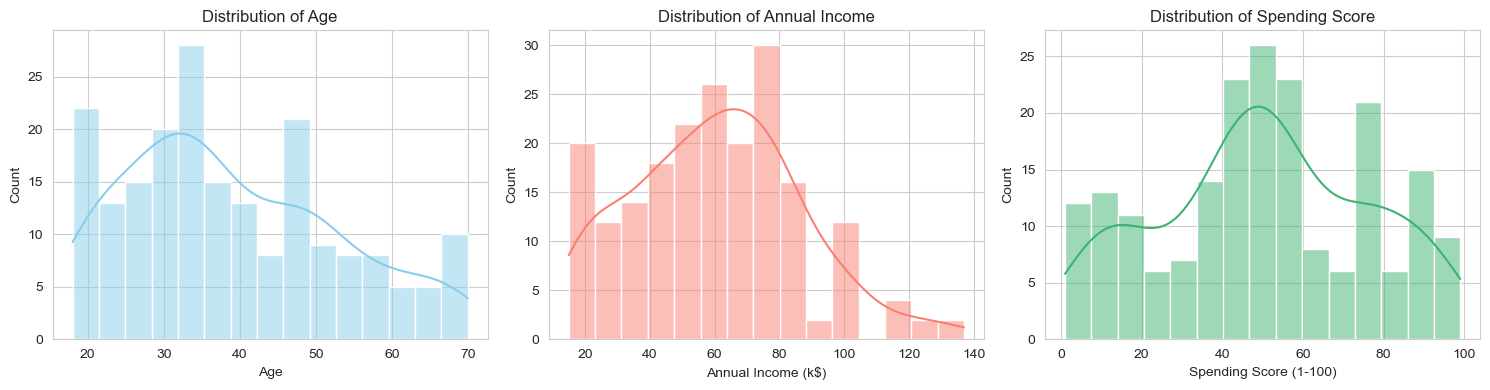

In [7]:
# Distribution of Age, Annual Income, and Spending Score
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df['Age'], bins=15, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Age')

sns.histplot(df['Annual Income (k$)'], bins=15, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Annual Income')

sns.histplot(df['Spending Score (1-100)'], bins=15, kde=True, ax=axes[2], color='mediumseagreen')
axes[2].set_title('Distribution of Spending Score')

plt.tight_layout()
plt.show()

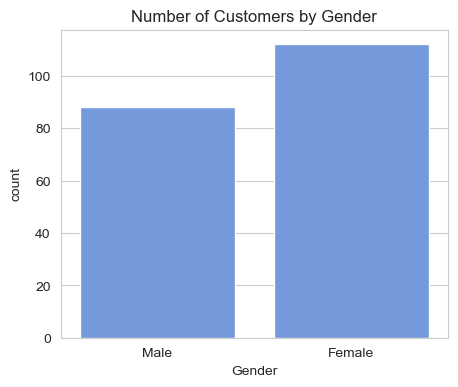

In [8]:
# How many male vs female customers do we have?
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='Gender', color='cornflowerblue')
plt.title('Number of Customers by Gender')
plt.show()

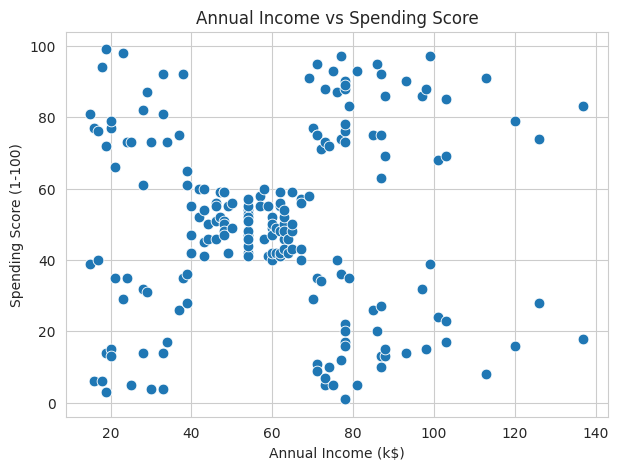

In [ ]:
# This is the MOST IMPORTANT chart.
# We plot Annual Income against Spending Score to see if natural "groups" of customers are visible even to the naked eye.
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', s=60)
plt.title('Annual Income vs Spending Score')
plt.show()

## 4. Select the Features for Clustering

K-Means needs to know WHICH columns to use to
measure "similarity" between customers. We can't use every column blindly:

- `CustomerID` -- just a label, has no real meaning, so we drop it.
- `Gender` -- not a number, we'll use it
  later just to *understand* the clusters, not to *create* them.
- `Age`, `Annual Income`, `Spending Score` -- all real numeric characteristics.

We will cluster customers using just:

- **Annual Income (k$)**
- **Spending Score (1-100)**

In [9]:
# Select just the two columns we want to cluster on
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

X.head()


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


## 5. Feature Scaling

K-Means decides which cluster a point belongs to by
measuring the **distance** between points (straight-line / Euclidean distance).

If one column has much bigger numbers than another, it will unfairly dominate that
distance calculation, and the algorithm will effectively ignore the smaller-scale column.

**Solution:** Since K-Means calculates the distance between data points, all features should be on the same scale. Therefore, we apply **Standardization**, which transforms each feature to have a **mean of 0** and a **standard deviation of 1**. This prevents features with larger values from dominating the distance calculation and allows every feature to contribute equally to the clustering process.


In [ ]:
# Create the scaler
scaler = StandardScaler()

# fit_transform does two things:
#   1. "fit"       -> learns the mean and standard deviation of each column
#   2. "transform" -> actually rescales the data using those values
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])
# Now the numbers are now roughly between -2 and 2, centered around 0, instead of being in the original "dollars" and "score" units.

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


## 6. Find the Best Number of Clusters -- The Elbow Method

K-Means needs us to tell it **how many clusters (K)**
to look for -- it doesn't decide this on its own. So the big question is: **what's
the right K for our data?**

We use a technique called the **Elbow Method**:

1. Try K-Means with K = 1, 2, 3, ... up to some maximum (say 10).
2. For each K, measure the **WCSS** (Within-Cluster Sum of Squares) -- a number that
   tells us how "tight" the clusters are (the total squared distance of every point
   from its own cluster's center). Lower WCSS = tighter clusters.
3. As K increases, WCSS always goes down (more clusters = smaller, tighter groups).
   But after a point, adding more clusters barely helps.
4. Plotting K vs WCSS gives a bent-arm shape -- the "elbow" (the bend) is usually the
   best choice for K. Past the elbow we're just overcomplicating the model for very
   little benefit.


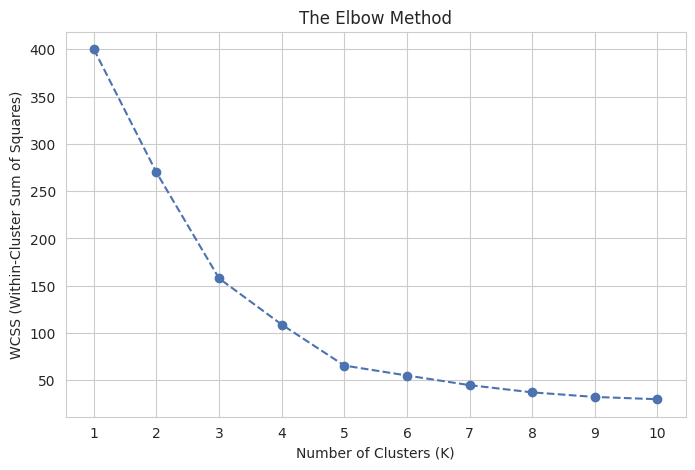

In [ ]:
wcss = []  # will store the WCSS value for each K we try

k_range = range(1, 11)  # test K from 1 to 10

for k in k_range:
    kmeans_test = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans_test.fit(X_scaled)
    wcss.append(kmeans_test.inertia_)  # inertia_ is scikit-learn's name for WCSS

# Plot K (x-axis) vs WCSS (y-axis)
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='#4C72B0')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(list(k_range))
plt.show()

# Look for the point where the line stops dropping sharply and starts to flatten out -- that "elbow" is our best guess for K.


## 7. Double-Check with the Silhouette Score

Let's confirm our choice with a second, more precise
metric: the **Silhouette Score**.

For each customer, this score compares:
- how close they are to other customers **in their own cluster**, vs.
- how close they are to customers **in the nearest other cluster**.

The score ranges from **-1 to 1**:
- **Close to 1** -> fits its own cluster well and is far from other clusters (great).
- **Close to 0** -> sits right on the border between two clusters.
- **Negative** -> probably in the wrong cluster.

We compute the *average* silhouette score across all customers, for each K, and pick
the K with the highest score. (This score needs at least 2 clusters, so we start at K=2.)


K = 2 -> Silhouette Score = 0.321
K = 3 -> Silhouette Score = 0.467
K = 4 -> Silhouette Score = 0.494
K = 5 -> Silhouette Score = 0.555
K = 6 -> Silhouette Score = 0.540
K = 7 -> Silhouette Score = 0.528
K = 8 -> Silhouette Score = 0.455
K = 9 -> Silhouette Score = 0.457
K = 10 -> Silhouette Score = 0.443


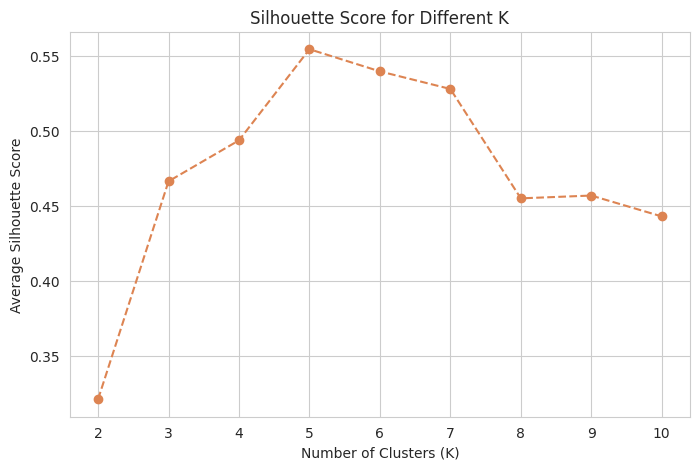

In [12]:
silhouette_scores = []
k_range_sil = range(2, 11)  # silhouette score needs at least 2 clusters

for k in k_range_sil:
    kmeans_test = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans_test.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"K = {k} -> Silhouette Score = {score:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(list(k_range_sil), silhouette_scores, marker='o', linestyle='--', color='#DD8452')
plt.title('Silhouette Score for Different K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Score')
plt.xticks(list(k_range_sil))
plt.show()


## 8. Train the Final K-Means Model

We now have strong evidence for the best K, from both
the elbow chart and the silhouette scores. Time to train our **final** model with
that value, and actually assign every customer to a cluster.


In [ ]:
optimal_k = 5

# Train K-Means with our chosen K
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)

# fit_predict trains the model AND returns the cluster label for every row
cluster_labels = kmeans.fit_predict(X_scaled)

# Add the cluster label back onto our original (unscaled) dataframe, so it's easy to read
df['Cluster'] = cluster_labels

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


## 9. Visualize the Clusters

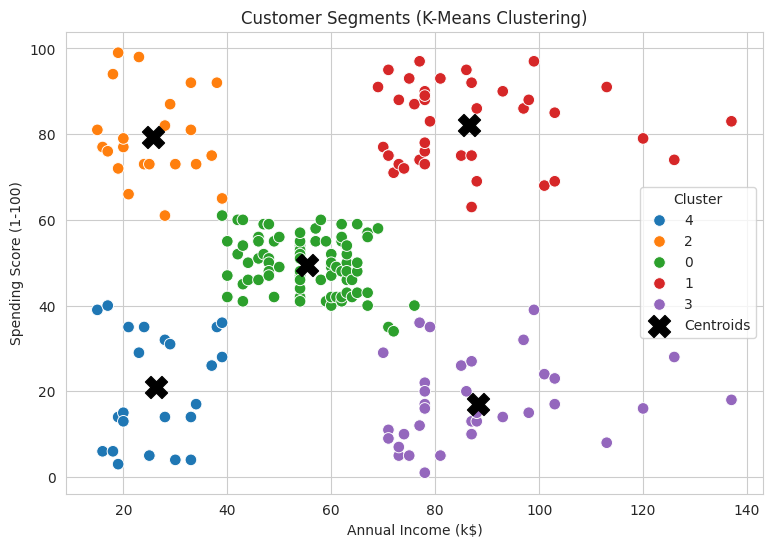

In [14]:
plt.figure(figsize=(9, 6))

# Plot each customer, colored by their cluster
sns.scatterplot(
    data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
    hue=df['Cluster'].astype(str), palette='tab10', s=70
)

centers_scaled = kmeans.cluster_centers_
centers_original = scaler.inverse_transform(centers_scaled)

# Plot the centroids (the "center point" of each cluster) as black X marks
plt.scatter(
    centers_original[:, 0], centers_original[:, 1],
    marker='X', s=250, c='black', label='Centroids'
)

plt.title('Customer Segments (K-Means Clustering)')
plt.legend(title='Cluster')
plt.show()


## 10. Understand What Each Cluster Actually Means

In [ ]:
# Average feature values per cluster
cluster_summary = df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean().round(1)

cluster_summary['Number of Customers'] = df['Cluster'].value_counts().sort_index()

cluster_summary


,Age,Annual Income (k$),Spending Score (1-100),Number of Customers
Cluster,,,,
0,42.7,55.3,49.5,81
1,32.7,86.5,82.1,39
2,25.3,25.7,79.4,22
3,41.1,88.2,17.1,35
4,45.2,26.3,20.9,23


In [ ]:
income_33, income_66 = df['Annual Income (k$)'].quantile([0.33, 0.66])
spending_33, spending_66 = df['Spending Score (1-100)'].quantile([0.33, 0.66])

def bucket(value, low_cut, high_cut):
    # Turns a number into 'Low', 'Medium', or 'High'
    if value <= low_cut:
        return "Low"
    elif value <= high_cut:
        return "Medium"
    else:
        return "High"

def label_cluster(row):
    income_level = bucket(row['Annual Income (k$)'], income_33, income_66)
    spending_level = bucket(row['Spending Score (1-100)'], spending_33, spending_66)
    return f"{income_level} Income, {spending_level} Spending"

cluster_summary['Segment Name'] = cluster_summary.apply(label_cluster, axis=1)
cluster_summary


,Age,Annual Income (k$),Spending Score (1-100),Number of Customers,Segment Name
Cluster,,,,,
0,42.7,55.3,49.5,81,"Medium Income, Medium Spending"
1,32.7,86.5,82.1,39,"High Income, High Spending"
2,25.3,25.7,79.4,22,"Low Income, High Spending"
3,41.1,88.2,17.1,35,"High Income, Low Spending"
4,45.2,26.3,20.9,23,"Low Income, Low Spending"


## 11. Save the Trained Model

We need to save **both**:
1. The `scaler` (to correctly scale any new customer's data the same way).
2. The `kmeans` model itself (to predict which cluster a new customer belongs to).


In [17]:
# Save the scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Save the trained K-Means model
with open('kmeans_model.pkl', 'wb') as f:
    pickle.dump(kmeans, f)

print("Model and scaler saved successfully!")
print("Files created: scaler.pkl, kmeans_model.pkl")


Model and scaler saved successfully!
Files created: scaler.pkl, kmeans_model.pkl
